In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ast 

from datasets import load_dataset

loaded_dataset = load_dataset("lukebarousse/data_jobs")

df = loaded_dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notnull(x) else x)


c:\Users\dee\anaconda3\envs\data_analysis\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
df_DA_UK = df[(df['job_title_short'] == 'Data Analyst') & (df['job_country'] == 'United Kingdom')]

df_DA_UK['salary_year_avg_gbp'] = df_DA_UK['salary_year_avg'] * 0.7454

df_DA_UK = df_DA_UK.dropna(subset=['salary_year_avg_gbp'])

df_DA_UK_exploded = df_DA_UK.explode('job_skills')

df_DA_UK_exploded[['job_skills', 'salary_year_avg_gbp', 'salary_year_avg']].head()

,job_skills,salary_year_avg_gbp,salary_year_avg
2602,excel,38025.8356,51014.0
2602,word,38025.8356,51014.0
2602,outlook,38025.8356,51014.0
16526,sql,74912.7000,100500.0
16526,jupyter,74912.7000,100500.0


In [4]:
df_DA_Skills = (
    df_DA_UK_exploded.groupby('job_skills')
    .agg(
        skills_count=('job_skills', 'size'),
        median_salary_gbp=('salary_year_avg_gbp', 'median'),
        median_salary=('salary_year_avg', 'median'),
    ).sort_values(by='skills_count', ascending=False)
)

df_DA_Skills = df_DA_Skills.rename(columns={'count':'skills_count', 'median':'median_salary_gbp'})
    
DA_jobs_count = len(df_DA_UK)      # Find count of Data Analyst jobs in US with salary info

df_DA_Skills['skills_percent'] = df_DA_Skills['skills_count'] / DA_jobs_count * 100

Skill_limit = 5 

df_DA_Skills_high_demand = df_DA_Skills[df_DA_Skills['skills_count'] > Skill_limit]

df_DA_Skills_high_demand


,skills_count,median_salary_gbp,median_salary,skills_percent
job_skills,,,,
sql,33,73421.9000,98500.0,45.833333
excel,29,56314.9700,75550.0,40.277778
python,25,66415.1400,89100.0,34.722222
tableau,13,74912.7000,100500.0,18.055556
r,9,57408.8445,77017.5,12.500000
go,9,52923.4000,71000.0,12.500000
sas,8,59637.2178,80007.0,11.111111
power bi,7,66415.1400,89100.0,9.722222
looker,6,71567.7175,96012.5,8.333333


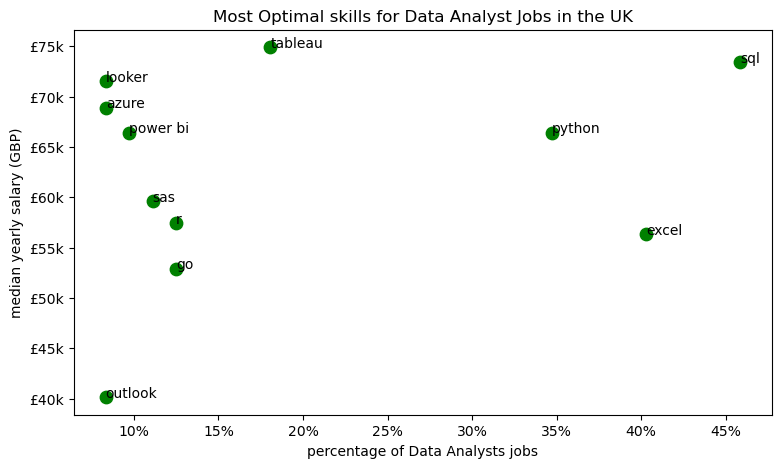

In [5]:
# Create a scatter plot to visualize the relationship between the percentage of Data Analyst jobs that require specific skills and the median salary for those skills.


df_DA_Skills_high_demand.plot(kind = 'scatter', x = 'skills_percent', y = 'median_salary_gbp', color = 'green', s = 80, figsize = (9, 5))
plt.xlabel('percentage of Data Analysts jobs')
plt.ylabel('median yearly salary (GBP)')
plt.title('Most Optimal skills for Data Analyst Jobs in the UK')

for i, txt in enumerate(df_DA_Skills_high_demand.index):
    plt.text(
        df_DA_Skills_high_demand['skills_percent'].iloc[i],
        df_DA_Skills_high_demand['median_salary_gbp'].iloc[i],
        txt
    )

# funformatter & percentformatter
from matplotlib.ticker import PercentFormatter

ax = plt.gca()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, pos: f'£{y/1000:,.0f}k'))
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
plt.show()

In [6]:
# Coloring by Technology

df_technology = df['job_type_skills'].copy()

df_technology = df_technology.drop_duplicates()       # remove duplicates

df_technology = df_technology.dropna()                 # remove null values

# combine all dictionaries into one

technology_dict = {}

for row in df_technology:
    row_dict = ast.literal_eval(row)
    for key, value in row_dict.items():
        if key in technology_dict:                   # if key already exists in technology_dict, add value to existing value
            technology_dict[key] += value
        else:                                        # if key does not exist in technology_dict, add key and value
            technology_dict[key] = value


# remove duplicates by converting values to set then back to list
for key, value in technology_dict.items():
    technology_dict[key] = list(dict.fromkeys(value))


technology_dict 

{'analyst_tools': ['power bi',
  'tableau',
  'dax',
  'excel',
  'powerpoint',
  'qlik',
  'sap',
  'looker',
  'word',
  'sas',
  'spss',
  'microstrategy',
  'cognos',
  'outlook',
  'splunk',
  'alteryx',
  'ssis',
  'sharepoint',
  'ms access',
  'visio',
  'datarobot',
  'ssrs',
  'spreadsheet',
  'sheets',
  'powerbi',
  'nuix',
  'msaccess',
  'esquisse'],
 'programming': ['r',
  'python',
  'sql',
  'nosql',
  'c#',
  'c++',
  'java',
  'matlab',
  'bash',
  'mongodb',
  'php',
  'go',
  'ruby',
  'javascript',
  'powershell',
  'apl',
  'scala',
  'mongo',
  'shell',
  'sas',
  'vba',
  'c',
  'html',
  'css',
  'lua',
  'perl',
  'golang',
  't-sql',
  'typescript',
  'sass',
  'visual basic',
  'solidity',
  'swift',
  'kotlin',
  'julia',
  'fortran',
  'no-sql',
  'groovy',
  'crystal',
  'rust',
  'assembly',
  'dart',
  'f#',
  'cobol',
  'objective-c',
  'vb.net',
  'elixir',
  'pascal',
  'lisp',
  'clojure',
  'delphi',
  'erlang',
  'haskell',
  'ocaml',
  'visualba

In [7]:
# Convert the dictionary into a DataFrame
df_technology = pd.DataFrame(list(technology_dict.items()), columns=['Technology', 'Skills'])

df_technology = df_technology.explode('Skills')

df_technology

,Technology,Skills
0,analyst_tools,power bi
0,analyst_tools,tableau
0,analyst_tools,dax
0,analyst_tools,excel
0,analyst_tools,powerpoint
...,...,...
9,sync,webex
9,sync,wire
9,sync,mattermost
9,sync,google chat


In [8]:
# merge with the high demand dataframe

df_plot = df_DA_Skills_high_demand.merge(df_technology, left_on = 'job_skills', right_on = 'Skills')

df_plot


,skills_count,median_salary_gbp,median_salary,skills_percent,Technology,Skills
0,33,73421.9000,98500.0,45.833333,programming,sql
1,29,56314.9700,75550.0,40.277778,analyst_tools,excel
2,25,66415.1400,89100.0,34.722222,programming,python
3,13,74912.7000,100500.0,18.055556,analyst_tools,tableau
4,9,57408.8445,77017.5,12.500000,programming,r
5,9,52923.4000,71000.0,12.500000,programming,go
6,8,59637.2178,80007.0,11.111111,analyst_tools,sas
7,8,59637.2178,80007.0,11.111111,programming,sas
8,7,66415.1400,89100.0,9.722222,analyst_tools,power bi
9,6,71567.7175,96012.5,8.333333,analyst_tools,looker


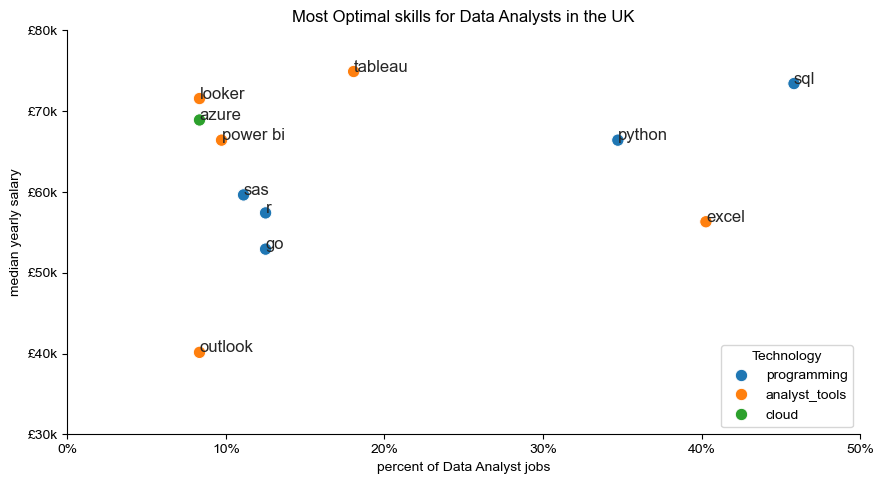

In [9]:
# plot the data using a scatterplot


plt.figure(figsize=(9, 5))
sns.scatterplot(data=df_plot, x='skills_percent', y='median_salary_gbp', hue='Technology', s=80)

sns.despine()
sns.set_theme(style='ticks')


plt.xlabel('percent of Data Analyst jobs')
plt.ylabel('median yearly salary')
plt.title('Most Optimal skills for Data Analysts in the UK')
plt.ylim(30000, 80000)
plt.xlim(0, 50)

for i, txt in enumerate(df_DA_Skills_high_demand.index):
    plt.text(
        df_DA_Skills_high_demand['skills_percent'].iloc[i],
        df_DA_Skills_high_demand['median_salary_gbp'].iloc[i],
        txt
    )

# funformatter & percentformatter
from matplotlib.ticker import PercentFormatter

ax = plt.gca()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, pos: f'£{y/1000:,.0f}k'))
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))

plt.tight_layout()
plt.show()
